# HW1_convolution

下方為欲測試的圖片原始圖：
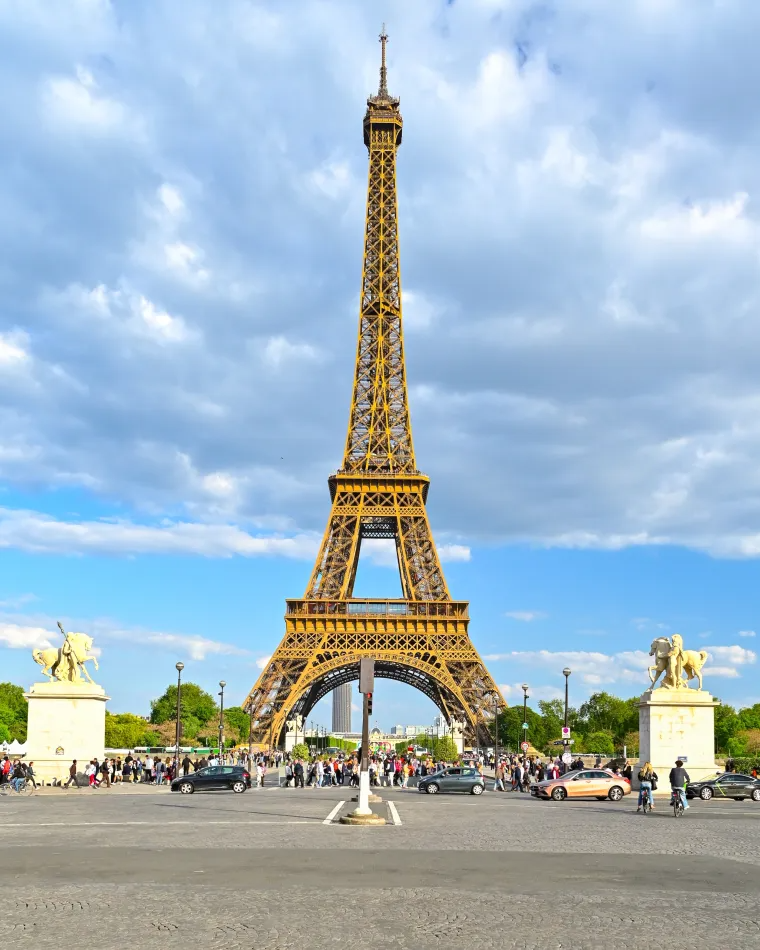
$\qquad$這張影像包含了艾菲爾鐵塔極為複雜且密集的金屬鋼骨結構，以及背景雲朵的柔和邊緣。
因此，我想嘗試看看卷積能不能精準地將鐵塔的幾何線條與輪廓特徵提取出來，並觀察差異。

In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


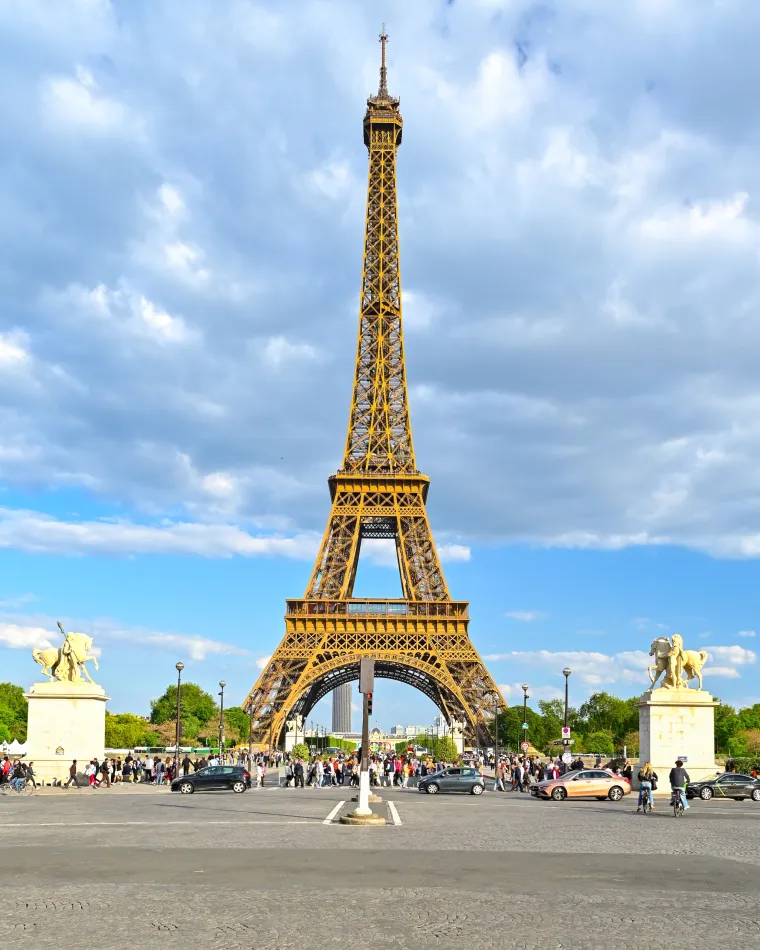

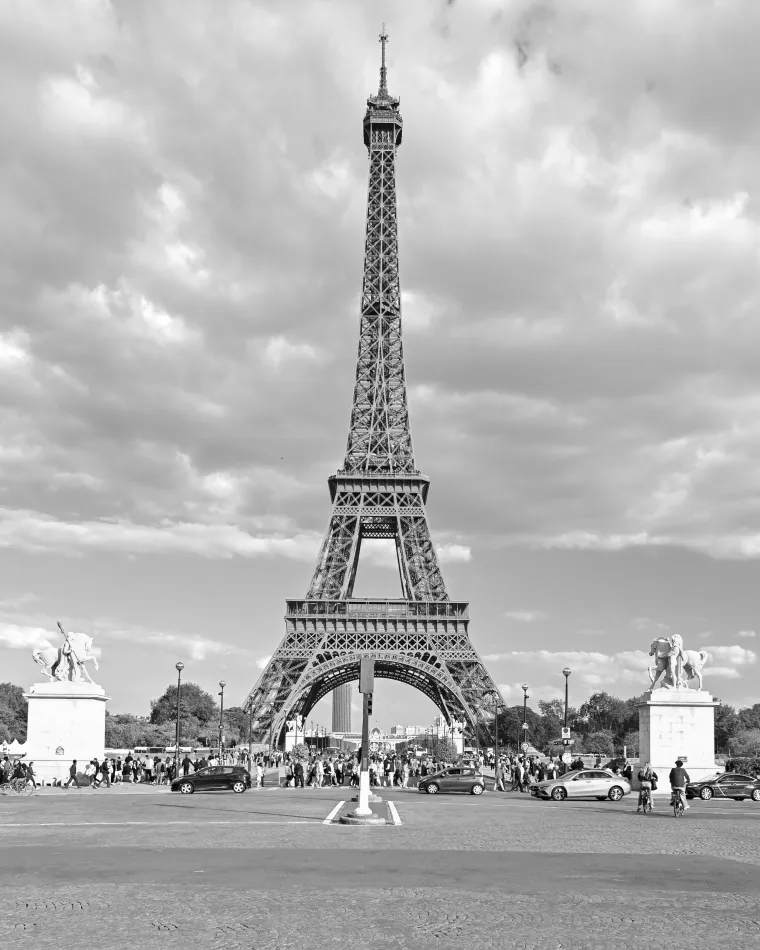

In [2]:
import cv2
from google.colab.patches import cv2_imshow

path = '/content/drive/MyDrive/Python_Lab/img'

img = cv2.imread(path + '/paris.jpeg')
cv2_imshow(img) 
img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
cv2_imshow(img_gray)

完成原始圖片的讀取和顯示的測試

## 針對影像進行零填補
$\qquad$要確保影像經過濾波後尺寸不變，因此，採用零填補，在影像周圍補上一圈數值為 $0$ 的像素。

$\qquad$零填補所需尺寸的尺寸公式：
$$
L_{out} = \frac{L-K+2P}{S} +1
$$
- L : 對應原始圖片的 H or W (高，寬)
- K : 對應卷積核的 H or W (高，寬)
- P : 由中心看左側或右側，單側的填補數
- S : 卷積核單次移動的像素



In [ ]:
import numpy as np

def zero_pad(img, kernel_size):
    pad_size = kernel_size // 2
    padded_img = np.pad(
        img, 
        pad_size
    )
    return padded_img

## Kernel 的定義

In [4]:
kernel_1 = (1.0/9.0) * np.array([
    [1, 1, 1],
    [1, 1, 1],
    [1, 1, 1]
])

# 自行完成
kernel_2 = None

kernel_3 = None

## Kernel 的應用與原圖


Original Image Shape: (950, 760)
Padded Image Shape: (952, 762)
Frame Shape: (950, 760, 3, 3)
Output K1 Shape: (950, 760)


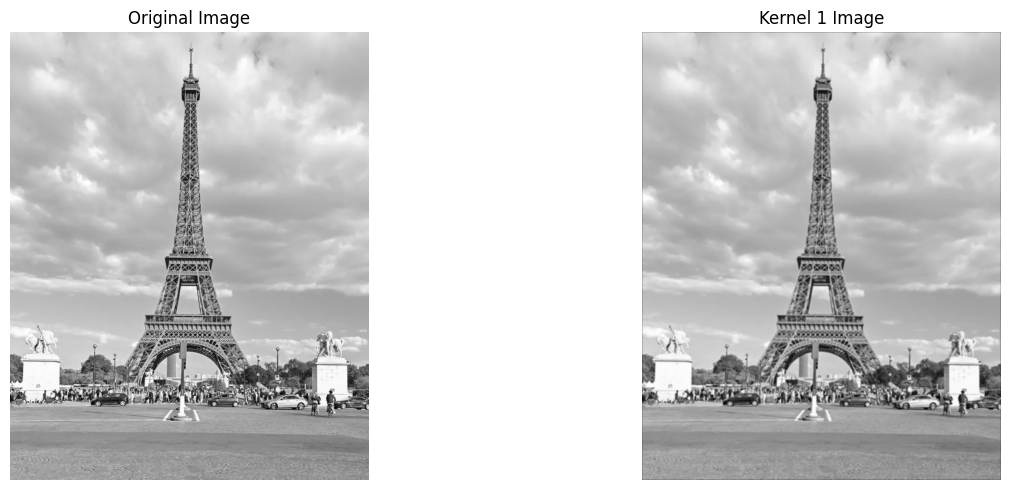

In [5]:
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view

kernel_size = kernel_1.shape[0]
print("Original Image Shape:", img_gray.shape)

padded_img = zero_pad(img_gray, kernel_size)
print("Padded Image Shape:", padded_img.shape)

frame = sliding_window_view(padded_img, (kernel_size, kernel_size))
print("Frame Shape:", frame.shape)

output_k1 = np.sum(frame * kernel_1, axis=(2, 3))
print("Output K1 Shape:", output_k1.shape)
output_k1 = np.clip(output_k1, 0, 255).astype(np.uint8)

plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_gray, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(output_k1, cmap='gray')
plt.title('Kernel 1 Image')
plt.axis('off')


plt.tight_layout()
plt.show()

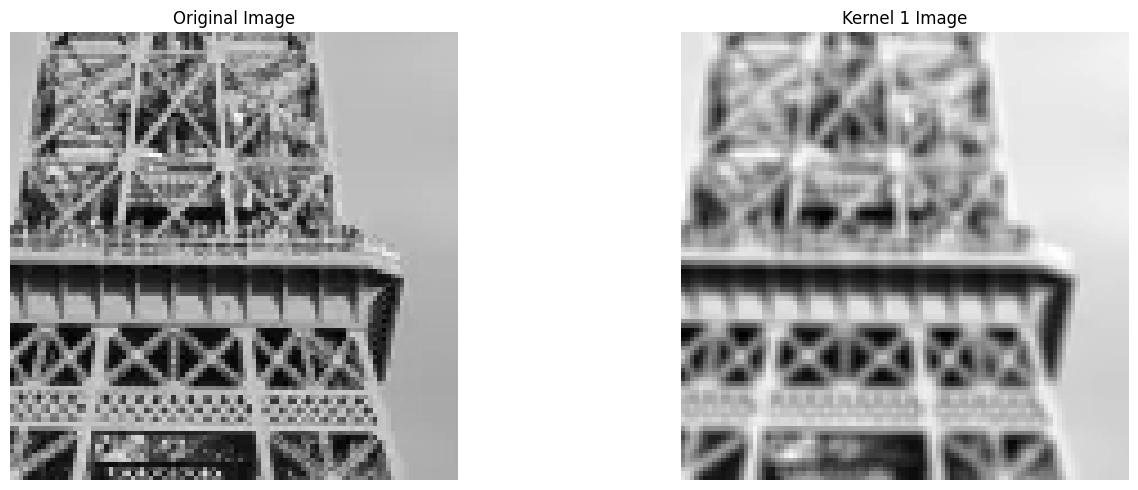

In [7]:
H, W = img_gray.shape

y1, y2 = int(H * 0.45), int(H * 0.45)+100
x1, x2 = int(W * 0.45), int(W * 0.45)+100

plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_gray[y1:y2, x1:x2], cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(output_k1[y1:y2, x1:x2], cmap='gray')
plt.title('Kernel 1 Image')
plt.axis('off')

plt.tight_layout()
plt.show()

$\qquad$從局部的鐵塔區域放大對比，可以明顯看出，不同卷積核產生的具體效果，K1 相鄰像素的數值被平均化了，達到了模糊的效果，K2 平坦區域為黑色，邊緣處與細節部份的數值劇烈變化，形成類雪花的雜訊效果，K3 影像的明暗對比變得比原圖明顯，且邊緣明顯更銳利和清晰，甚至有點光暈。

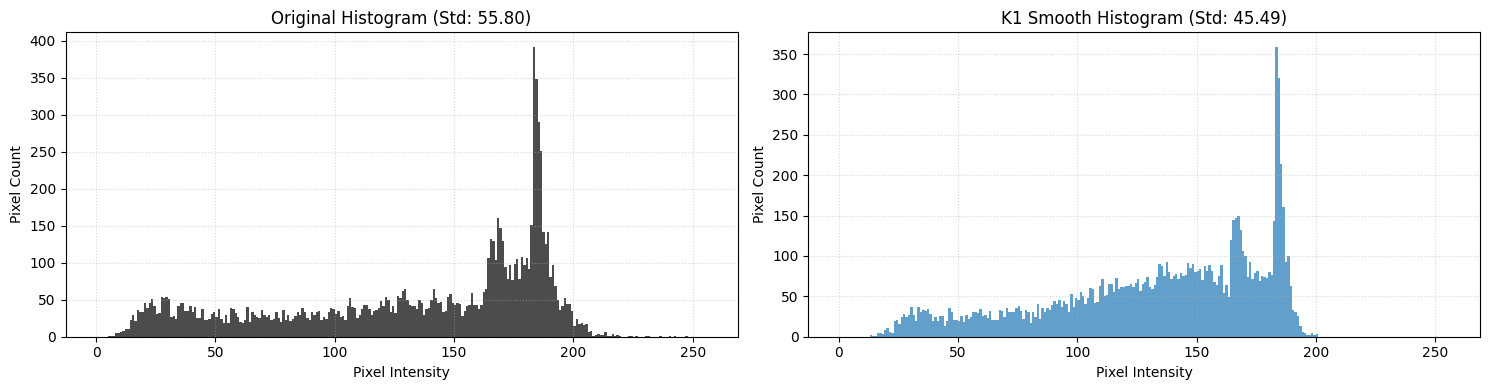

In [8]:
plt.figure(figsize=(15, 4))

plt.subplot(1, 2, 1)
plt.hist(img_gray[y1:y2, x1:x2].ravel(), bins=256, range=[0, 256], color='black', alpha=0.7)
plt.title(f'Original Histogram (Std: {np.std(img_gray[y1:y2, x1:x2]):.2f})')
plt.xlabel('Pixel Intensity')
plt.ylabel('Pixel Count')
plt.grid(True, linestyle=':', alpha=0.5)

plt.subplot(1, 2, 2)
plt.hist(output_k1[y1:y2, x1:x2].ravel(), bins=256, range=[0, 256], color='tab:blue', alpha=0.7)
plt.title(f'K1 Smooth Histogram (Std: {np.std(output_k1[y1:y2, x1:x2]):.2f})')
plt.xlabel('Pixel Intensity')
plt.ylabel('Pixel Count')
plt.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

$\qquad$從局部的鐵塔區域放大直方圖對比，可以明顯看出，原圖的灰階分佈較廣，K1 相鄰像素的數值被平均化了，直方圖變得更狹窄，且標準差下降，達到了模糊的效果，K2 平坦區域為黑色，大多數像素擠在靠0的位置，而最亮處還是有不少的分佈，為邊緣區，K3 影像的明暗對比變得比原圖極端，中間灰階顯著減少，標準差顯著提高。

In [9]:
def calc_metrics(img_roi, name):
    roi = img_roi.astype(float)
    std_val = np.std(roi)

    gx = cv2.Sobel(roi, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(roi, cv2.CV_64F, 0, 1, ksize=3)
    
    grad_mag = np.sqrt(gx**2 + gy**2)
    
    mean_gx = np.mean(np.abs(gx))
    mean_gy = np.mean(np.abs(gy))
    mean_grad = np.mean(grad_mag)
    
    print(f"{name:<28s} std={std_val:7.2f}   |dx|={mean_gx:6.2f}   |dy|={mean_gy:6.2f}   grad={mean_grad:6.2f}")

print("=== 量化 ===")
calc_metrics(img_gray[y1:y2, x1:x2] , "Original")
calc_metrics(output_k1[y1:y2, x1:x2], "K1 Blur  ")

=== 量化 ===
Original                     std=  55.80   |dx|=113.33   |dy|=119.20   grad=189.88
K1 Blur                      std=  45.49   |dx|= 68.38   |dy|= 79.25   grad=120.45


$\qquad$利用 Sobel 運算子可以計算和評估影像的梯度關係，從數據來看 K1 標準差由 55.8 -> 45.49, 且梯度由 189.88 -> 120.45 皆明顯下降，證明影像確實被模糊了，K2 其標準差與梯度皆高於原圖，也確實整理的邊緣更為明顯，K3 其標準差 92.12 與梯度 368.63 皆為最高的，是原圖的將近兩倍，證明其銳化效果明顯。

## 解析
- Kernel 1: 被模糊化了，原因是 Kernel 1 基本上就是一個平均的操作，3*3 卷積核有 9 個，乘上 1/9 就是該像素的大小被完全平均掉了，每個像素都這樣的話，一個影像彼此的差異就沒有原始的大了，細節也會被弱化一些。
- Kernel 2: 變成只保留邊緣，其餘平坦都被濾除了，原因是中間數值剛好可以被上下左右的減去，所以平坦部份自然最後就會是 0 。
- Kernel 3: 雖然對比 Kernel 2 只把中間變成 5，但效果差異很大，變成大致和原圖沒有差異，但是邊緣銳利化了，原因是假設平坦區皆為 100，相減後像素還是 100 被保留了，但是邊緣區域如果亮的就會更大。
## 自訂應用
$\qquad$ 嘗試延伸使用 5 * 5 做銳化核，可以發現 5 * 5 明顯比 3 * 3 的效果更為明顯的，而中央 17 與 18 的話，17 還是看得到很多元素，但是 18 就會發現幾乎平坦變成全白，而建築之類的相當明顯，整體呈現類似鉛筆素描的簡潔感

In [ ]:
kernel_sharpen_5x5_1 = np.array([
    [ 0,  0, -1,  0,  0],
    [ 0, -1, -2, -1,  0],
    [-1, -2, 16, -2, -1],
    [ 0, -1, -2, -1,  0],
    [ 0,  0, -1,  0,  0]
])

kernel_sharpen_5x5_2 = np.array([
    [ 0,  0, -1,  0,  0],
    [ 0, -1, -2, -1,  0],
    [-1, -2, 17, -2, -1],
    [ 0, -1, -2, -1,  0],
    [ 0,  0, -1,  0,  0]
])

kernel_sharpen_5x5_3 = np.array([
    [ 0,  0, -1,  0,  0],
    [ 0, -1, -2, -1,  0],
    [-1, -2, 18, -2, -1],
    [ 0, -1, -2, -1,  0],
    [ 0,  0, -1,  0,  0]
])

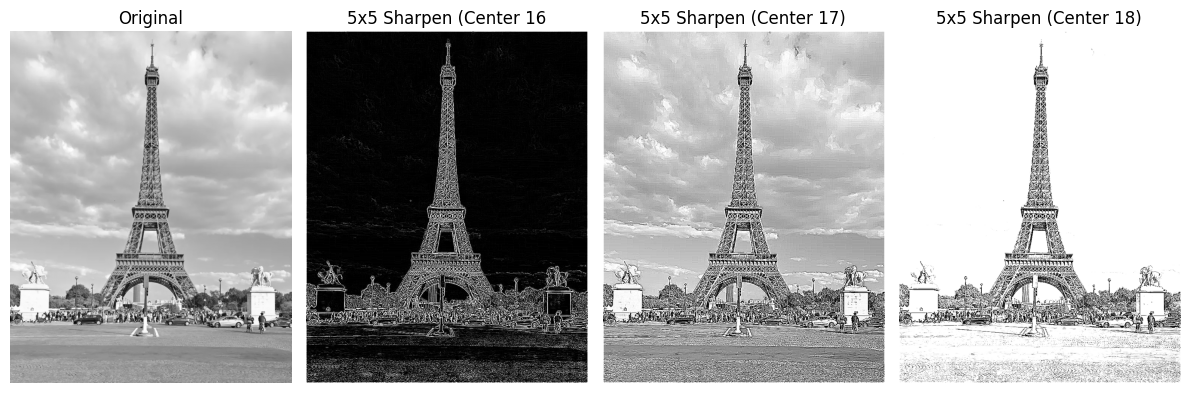

In [ ]:
kernel_size = 5

padded_img = zero_pad(img_gray, kernel_size)
frame_5x5 = sliding_window_view(padded_img, (kernel_size, kernel_size))

output_sharpen_1 = np.sum(frame_5x5 * kernel_sharpen_5x5_1, axis=(2, 3))
output_sharpen_2 = np.sum(frame_5x5 * kernel_sharpen_5x5_2, axis=(2, 3))   
output_sharpen_3 = np.sum(frame_5x5 * kernel_sharpen_5x5_3, axis=(2, 3))     

output_sharpen_1 = np.clip(output_sharpen_1, 0, 255)
output_sharpen_2 = np.clip(output_sharpen_2, 0, 255)
output_sharpen_3 = np.clip(output_sharpen_3, 0, 255)

plt.figure(figsize=(12, 6))

plt.subplot(1, 4, 1)
plt.imshow(img_gray, cmap='gray')
plt.title('Original')
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(output_sharpen_1, cmap='gray')
plt.title('5x5 Sharpen (Center 16')
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(output_sharpen_2, cmap='gray')
plt.title('5x5 Sharpen (Center 17)')
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(output_sharpen_3, cmap='gray')
plt.title('5x5 Sharpen (Center 18)')
plt.axis('off')

plt.tight_layout()
plt.show()

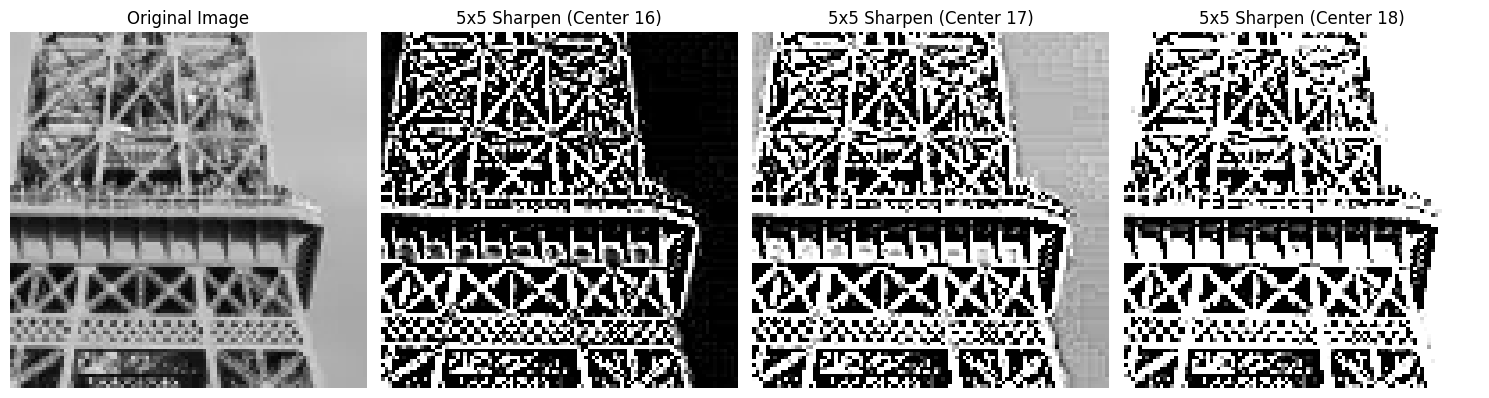

In [ ]:
H, W = img_gray.shape

y1, y2 = int(H * 0.45), int(H * 0.45)+100
x1, x2 = int(W * 0.45), int(W * 0.45)+100

plt.figure(figsize=(15, 5))

plt.subplot(1, 4, 1)
plt.imshow(img_gray[y1:y2, x1:x2], cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(output_sharpen_1[y1:y2, x1:x2], cmap='gray')
plt.title('5x5 Sharpen (Center 16)')
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(output_sharpen_2[y1:y2, x1:x2], cmap='gray')
plt.title('5x5 Sharpen (Center 17)')
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(output_sharpen_3[y1:y2, x1:x2], cmap='gray')
plt.title('5x5 Sharpen (Center 18)')
plt.axis('off')

plt.tight_layout()
plt.show()

$\qquad$原始圖保留了鐵塔原始影像的局部放大，5x5 Sharpen (Center 17) & (Center 18) 相比於原圖，邊緣處皆相當顯著，且整體更為明亮，但Center 18 的銳化程度比 17 更極端，但邊緣處開始出現失真。

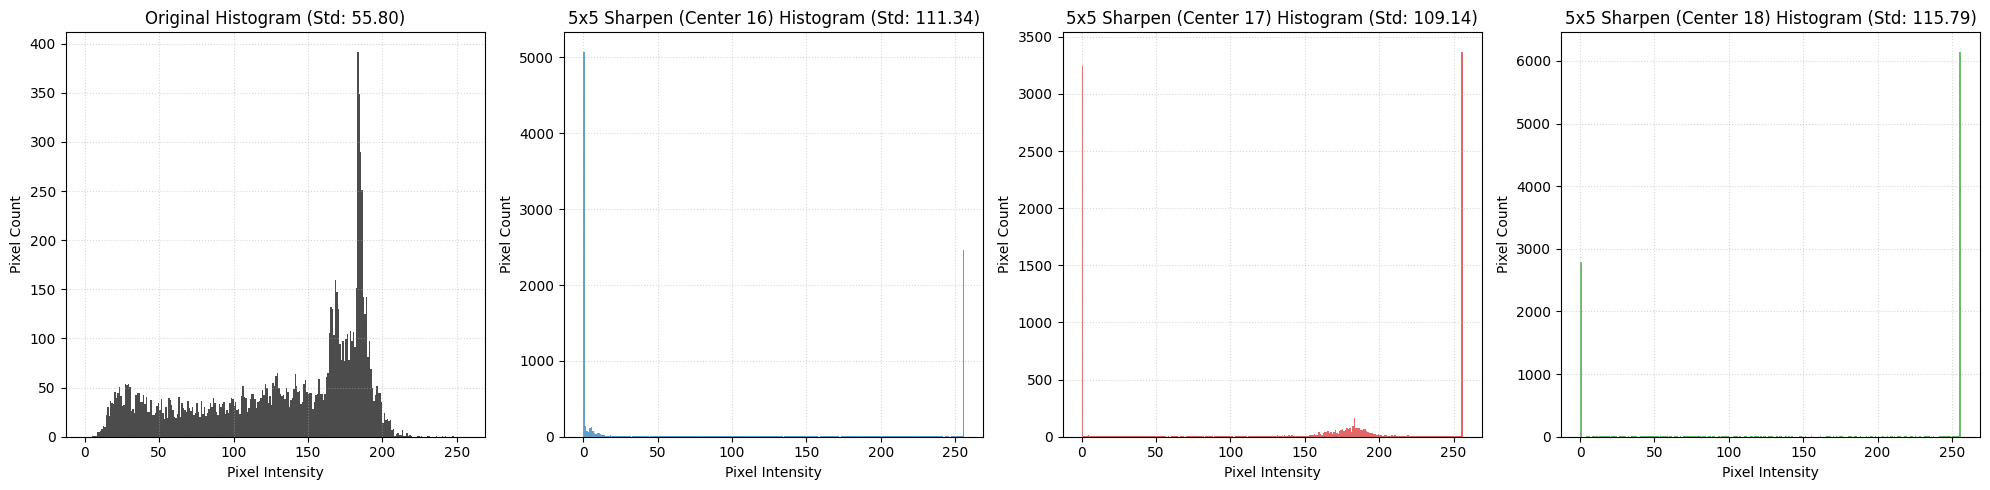

In [ ]:
plt.figure(figsize=(20, 5))

plt.subplot(1, 4, 1)
plt.hist(img_gray[y1:y2, x1:x2].ravel(), bins=256, range=[0, 256], color='black', alpha=0.7)
plt.title(f'Original Histogram (Std: {np.std(img_gray[y1:y2, x1:x2]):.2f})')
plt.xlabel('Pixel Intensity')
plt.ylabel('Pixel Count')
plt.grid(True, linestyle=':', alpha=0.5)

plt.subplot(1, 4, 2)
plt.hist(output_sharpen_1[y1:y2, x1:x2].ravel(), bins=256, range=[0, 256], color='tab:blue', alpha=0.7)
plt.title(f'5x5 Sharpen (Center 16) Histogram (Std: {np.std(output_sharpen_1[y1:y2, x1:x2]):.2f})')
plt.xlabel('Pixel Intensity')
plt.ylabel('Pixel Count')
plt.grid(True, linestyle=':', alpha=0.5)

plt.subplot(1, 4, 3)
plt.hist(output_sharpen_2[y1:y2, x1:x2].ravel(), bins=256, range=[0, 256], color='tab:red', alpha=0.7)
plt.title(f'5x5 Sharpen (Center 17) Histogram (Std: {np.std(output_sharpen_2[y1:y2, x1:x2]):.2f})')
plt.xlabel('Pixel Intensity')
plt.ylabel('Pixel Count')
plt.grid(True, linestyle=':', alpha=0.5)

plt.subplot(1, 4, 4)
plt.hist(output_sharpen_3[y1:y2, x1:x2].ravel(), bins=256, range=[0, 256], color='tab:green', alpha=0.7)
plt.title(f'5x5 Sharpen (Center 18) Histogram (Std: {np.std(output_sharpen_3[y1:y2, x1:x2]):.2f})')
plt.xlabel('Pixel Intensity')
plt.ylabel('Pixel Count')
plt.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

$\qquad$原始圖保留了鐵塔原始影像的局部放大，像素分佈均勻涵蓋了 0 到 255 的範圍，5×5 銳化 Center 17 中間的灰階幾乎完全消失，像素極端地往兩側，證實其為銳利化，5×5 銳化 Center 18 情況比 Center 17 更極端，幾乎全部擠在 0 和 255 這兩根柱子上，對比度和影像的失真都更為明顯。

In [ ]:
def calc_metrics(img_roi, name):
    roi = img_roi.astype(float)
    std_val = np.std(roi)

    gx = cv2.Sobel(roi, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(roi, cv2.CV_64F, 0, 1, ksize=3)
    
    grad_mag = np.sqrt(gx**2 + gy**2)
    
    mean_gx = np.mean(np.abs(gx))
    mean_gy = np.mean(np.abs(gy))
    mean_grad = np.mean(grad_mag)
    
    print(f"{name:<28s} std={std_val:7.2f}   |dx|={mean_gx:6.2f}   |dy|={mean_gy:6.2f}   grad={mean_grad:6.2f}")

print("=== 量化 ===")
calc_metrics(img_gray [y1:y2, x1:x2], "Original")
calc_metrics(output_sharpen_1[y1:y2, x1:x2], "5x5 Sharpen (Center 16)")
calc_metrics(output_sharpen_2[y1:y2, x1:x2], "5x5 Sharpen (Center 17)")
calc_metrics(output_sharpen_3[y1:y2, x1:x2], "5x5 Sharpen (Center 18)")

=== 量化 ===
Original                     std=  55.80   |dx|=113.33   |dy|=119.20   grad=189.88
5x5 Sharpen (Center 16)      std= 111.34   |dx|=295.04   |dy|=293.66   grad=475.71
5x5 Sharpen (Center 17)      std= 109.14   |dx|=302.63   |dy|=299.60   grad=489.19
5x5 Sharpen (Center 18)      std= 115.79   |dx|=285.04   |dy|=282.53   grad=462.64


$\qquad$原始圖保留了鐵塔原始影像的局部放大後的 Sobel 運算成果，與原圖 std=55.80, grad=189.88 相比，5×5 Sharpen (Center 17) 與 (Center 18) 的標準差與梯度指標大幅提升，這證明了銳化卷積核確實能明顯增強邊緣。雖然 Center 18 的標準差更高，但其平均梯度卻反而差，顯示過度銳化的影響，證明了失真的可能性